# 295. Does any kmerseek setting reach ice-binding proteins of other lineages from one query?

This notebook holds the whole convergence test. Sections 1-7 are the ice-binding
proteins, the one class searched so far. Section 8 is the truth sets for three more
classes, adhesive, shell-matrix and silk proteins, built but not yet searched.

Ice-binding proteins, also called antifreeze proteins, stop ice crystals growing in an
animal, plant or microbe that lives below freezing. They arose separately several times:
in fish, type I, type II, type III and the antifreeze glycoprotein AFGP come from
different ancestral genes, and insects, plants, bacteria and fungi evolved their own. So
two ice-binding proteins from different lineages share a job and, in places, a
physicochemical pattern, but no common ancestor. A search that reads ancestry cannot
connect them.

**The question.** kmerseek matches k-mers in a reduced alphabet, so a hydrophobic and
polar pattern can match where the residues do not. If that is enough to carry a pattern
across lineages, then one ice-binding protein should reach the others. The test is
whether it does so better than methods that need no search at all.

**The decision this informs.** Whether the paper can claim that kmerseek finds proteins
that share a physicochemical pattern without shared ancestry. That claim is the whole
case for searching in a reduced alphabet rather than filtering a protein by its
composition. If a scan with no search reaches the same proteins, the search adds nothing
here and the claim comes out of the paper.

**The decision rule, fixed before the run** (from the task brief, 2026-10-14, and
unchanged since). PASS needs all three:

1. The kmerseek setting is chosen on the odd-numbered query lineages (1 fish type I,
   3 fish type II, 5 insects, 7 bacteria) and reported on the even-numbered ones
   (2 AFGP, 4 fish type III). Plants have no reviewed entry, so the even half is two
   lineages and both must pass.
2. On both held-out lineages, the chosen setting's cross-lineage recall beats the
   composition scan and the period scan by at least 0.10.
3. For those queries, the median number of ice-binding proteins a null draw reaches is at
   most 10% of the number the real query reaches.

Higher recall is better; 0 means the method reached no ice-binding protein of any other
lineage.

**The data.** The convergence-afp pipeline
([nextflow-runs/convergence-afp](../nextflow-runs/convergence-afp), PR 141), run on
Sherlock 15-16 October 2026 and scored on 17 October. Every method ranked all 575_748 entries of reviewed
Swiss-Prot release 2026_03 (FASTA MD5 `bc9d398533e6df582b563c6c03093bd0`) for every
query. kmerseek is 0.4 at commit
[3c353d4](https://github.com/seanome/kmerseek/pull/141), with the Karlin-Altschul
E-value path on, over the 230 settings of the dark-set midi run. A setting is one
alphabet, k-size, scaled value, low-complexity mask and mismatch penalty.

**Queries.** One reviewed entry per lineage, the one with the most experimental evidence
lines: P04002 (winter flounder, type I), P02732 (bald rockcod, AFGP), A0ZT93 (sea
poacher, type II), P07457 (ocean pout, type III), Q9GSA6 (spruce budworm, insect) and
H7FWB6 (*Flavobacterium frigoris*, bacterial). Each also got 20 draws of two controls:
null A shuffles the query's residues, keeping its composition; null B reorders positions
inside the repeat unit, keeping composition and repeat period but changing the word.

**How a method is compared.** There are no synthetic decoys. For each ranked list, the
threshold is the score of the first Swiss-Prot entry that is not an ice-binding protein
at all, and recall is the share of other-lineage ice-binding proteins scoring better than
that. A hit on the query's own lineage is never counted, in either the numerator or the
denominator. The scoring code is
[nextflow-runs/convergence-afp/bin/score.py](../nextflow-runs/convergence-afp/bin/score.py).

In [1]:
import json
import os
import re
import sys
import textwrap
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

sys.path.insert(0, str(Path.cwd()))
import pubfig as pf

pf.use_style()

SCORED = Path(
    os.environ.get("CONVERGENCE_SCORED", "~/data/convergence-afp/scored")
).expanduser()
TRUTH_DIR = Path("../data/convergence_afp")
FIGURES = Path("../figures")
FIGURES.mkdir(exist_ok=True)

metrics = pl.read_csv(SCORED / "metrics.tsv", separator="\t")
grid = pl.read_csv(SCORED / "grid.tsv", separator="\t")
verdict = json.loads((SCORED / "verdict.json").read_text())
afdb = pl.read_csv(SCORED / "afdb_coverage.tsv", separator="\t")
truth = pl.read_csv(TRUTH_DIR / "truth_set.tsv", separator="\t")
queries = pl.read_csv(TRUTH_DIR / "queries.tsv", separator="\t")
hits_md = (SCORED / "hits_residues.md").read_text()

# Real queries only, and only rows where a false positive set the threshold. A list with
# none has no recall: see bin/score.py.
real = metrics.filter((pl.col("kind") == "real") & pl.col("recall").is_not_null())
# Every setting the run was given, read from its own table: a setting whose E-value fit was
# refused writes no rows, so counting the metrics would miss it.
n_settings_total = pl.read_csv(
    "../nextflow-runs/convergence-afp/assets/kmerseek_settings.tsv", separator="\t"
).height

# One colour per method, kept for every figure in this notebook.
METHOD_COLOUR = {
    "kmerseek": pf.OKABE_ITO["blue"],
    "phmmer": pf.OKABE_ITO["vermillion"],
    "jackhmmer": pf.OKABE_ITO["orange"],
    "mmseqs2": pf.OKABE_ITO["reddish_purple"],
    "foldseek": pf.OKABE_ITO["bluish_green"],
    "composition": pf.OKABE_ITO["sky_blue"],
    "period": pf.OKABE_ITO["yellow"],
    "window": pf.OKABE_ITO["black"],
    "motif": pf.GREY,
}
METHOD_ORDER = [
    "kmerseek",
    "phmmer",
    "jackhmmer",
    "mmseqs2",
    "foldseek",
    "composition",
    "period",
    "window",
    "motif",
]
QUERY_LINEAGES = sorted(real["query_lineage"].unique())
TARGET_LINEAGES = sorted(truth["lineage"].unique())


def header(fig, tools, hypothesis, conclusion):
    """Tool, hypothesis and conclusion above the panels, with no empty band.

    pubfig builds figures with constrained layout, which reserves space for a suptitle
    but ignores subplots_adjust, so the header goes in the suptitle. The text is wrapped
    to the figure's own width: an unwrapped line runs off the page and over the panels.
    """
    n_chars = max(40, int(fig.get_figwidth() * 25.4 / 1.3))
    lines = []
    for label, text in [
        ("TOOLS", tools),
        ("HYPOTHESIS", hypothesis),
        ("CONCLUSION", conclusion),
    ]:
        lines += textwrap.wrap(f"{label}: {text}", n_chars)
    fig.suptitle("\n".join(lines), x=0.0, ha="left", va="bottom", fontsize=6)


def legend_in_axes(ax, ncol=1, loc="upper right"):
    """Legend in the panel's empty space.

    pubfig's shared legend goes in the band above the panels, which is where the header
    text goes, and the two overlapped.
    """
    ax.legend(loc=loc, ncol=ncol, frameon=False, fontsize=6)


# Every ranked list must hold every query, including the ones it reported nothing for.
# A list missing a query would make a median over the null draws a median over the draws
# that happened to hit something (bin/score.py, commit 653ddd1).
per_list = metrics.group_by("method", "setting_label", "overlap_min").len()
n_queries = metrics["query_id"].n_unique()
short = per_list.filter(pl.col("len") != n_queries)
assert (
    short.height == 0
), f"{short.height} ranked lists do not score all {n_queries} queries:\n{short}"
print(f"every one of the {per_list.height} ranked lists scores all {n_queries} queries")

print(
    f"metrics rows {metrics.height}, ranked lists {metrics['setting_label'].n_unique()}"
)
print(
    f"kmerseek settings {n_settings_total}, truth entries {truth.height}, queries {queries.height}"
)
print(f"verdict {verdict['verdict']}, chosen setting {verdict['chosen_setting']}")

every one of the 202 ranked lists scores all 246 queries
metrics rows 49692, ranked lists 200
kmerseek settings 230, truth entries 59, queries 6
verdict FAIL, chosen setting hsdm17.k6.s1.lcfalse.extend-c0.18


## 1. The truth set: 59 reviewed ice-binding proteins, and what Foldseek can see of them

Every reviewed UniProtKB entry matched by the keyword "Antifreeze protein" (KW-0047),
the Gene Ontology term "ice binding" (GO:0050825), or a protein-name search, in release
2026_03. The lineage comes from the entry's taxonomy, and for fish from the antifreeze
type in its family or name. `fish, type unknown` holds the three type IV proteins, which
UniProt places in the apolipoprotein family; they count as targets but have no query.

Two facts set the ceiling for the whole test. Plants have no reviewed entry, so there is
no plant query. And an entry with no AlphaFold model cannot be reached by Foldseek
searching structures, which is why panel b matters: 7 of the 8 insect entries, the spruce
budworm isoforms, have no model.

shape: (8, 4)
┌──────────────────────┬───────────┬──────────────────┬─────────────────┐
│ lineage              ┆ n_entries ┆ median_length_aa ┆ n_without_model │
│ ---                  ┆ ---       ┆ ---              ┆ ---             │
│ str                  ┆ u32       ┆ f64              ┆ i64             │
╞══════════════════════╪═══════════╪══════════════════╪═════════════════╡
│ 1 fish, type I AFP   ┆ 12        ┆ 82.0             ┆ 1               │
│ 2 fish, AFGP         ┆ 4         ┆ 25.0             ┆ 0               │
│ 3 fish, type II AFP  ┆ 3         ┆ 168.0            ┆ 0               │
│ 4 fish, type III AFP ┆ 19        ┆ 66.0             ┆ 0               │
│ 5 insects            ┆ 8         ┆ 110.0            ┆ 7               │
│ 7 bacteria           ┆ 4         ┆ 272.5            ┆ 0               │
│ 8 other              ┆ 6         ┆ 245.0            ┆ 1               │
│ fish, type unknown   ┆ 3         ┆ 125.0            ┆ 0               │
└──────────────────────┴

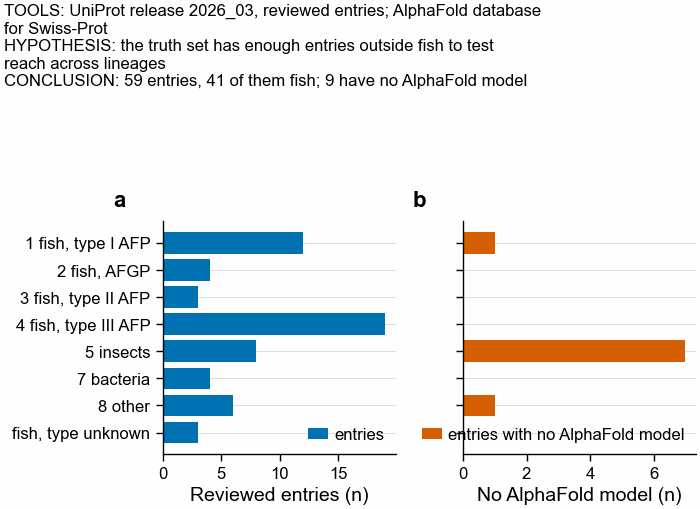

In [2]:
per_lineage = (
    truth.group_by("lineage")
    .agg(
        pl.len().alias("n_entries"), pl.col("Length").median().alias("median_length_aa")
    )
    .join(afdb.select("lineage", "n_without_model"), on="lineage", how="left")
    .sort("lineage")
)
print(per_lineage)
print()
print(
    queries.select("lineage", "Entry", "Protein names", "Length", "Organism").sort(
        "lineage"
    )
)

fig, axs = pf.figure(pf.ONE_COLUMN_MM, 55, ncols=2, sharey=True)
y = np.arange(per_lineage.height)
axs[0].barh(y, per_lineage["n_entries"], color=pf.OKABE_ITO["blue"], label="entries")
axs[1].barh(
    y,
    per_lineage["n_without_model"],
    color=pf.OKABE_ITO["vermillion"],
    label="entries with no AlphaFold model",
)
axs[0].set_yticks(y)
axs[0].set_yticklabels(per_lineage["lineage"])
axs[0].invert_yaxis()
axs[0].set_xlabel("Reviewed entries (n)")
axs[1].set_xlabel("No AlphaFold model (n)")
for ax in axs:
    ax.grid(axis="y", which="major")
    ax.set_axisbelow(True)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
legend_in_axes(axs[0], loc="lower right")
legend_in_axes(axs[1], loc="lower right")
header(
    fig,
    "UniProt release 2026_03, reviewed entries; AlphaFold database for Swiss-Prot",
    "the truth set has enough entries outside fish to test reach across lineages",
    f"{int(per_lineage['n_entries'].sum())} entries, "
    f"{int(per_lineage.filter(pl.col('lineage').str.starts_with('1 ') | pl.col('lineage').str.starts_with('2 ') | pl.col('lineage').str.starts_with('3 ') | pl.col('lineage').str.starts_with('4 ') | pl.col('lineage').str.starts_with('fish'))['n_entries'].sum())} of them fish; "
    f"{int(per_lineage['n_without_model'].sum())} have no AlphaFold model",
)
pf.save(fig, FIGURES / "295_SF1_truth_set_per_lineage_swissprot_2026_03")

## 2. What ran: 230 kmerseek settings, four existing tools and four scans with no search

A scan needs no search: it turns each protein into one description and ranks targets by
distance to the query's. The composition scan uses residue frequencies, in 20 letters and
in each kmerseek alphabet's classes. The period scan uses the hydrophobic-polar
autocorrelation and the Eisenberg hydrophobic moment. The hydropathy window scan slides a
Kyte-Doolittle window of 9 or 19 residues and matches the two profiles at their best
offset; because a short target matches a long query's best stretch over very few windows,
it is run at four minimum-overlap cutoffs and gets the best of them. The known-motif scan
applies the published repeat consensus for AFGP, fish type I and the spruce budworm.

Of the 230 kmerseek settings, 66 could not be searched at all: their Karlin-Altschul fit
was refused, so no E-value exists to rank by. Those are absent below rather than counted
as zero.

shape: (9, 5)
┌─────────────┬──────────────┬────────────────┬──────────────────────────┬─────────────┐
│ method      ┆ ranked_lists ┆ queries_ranked ┆ most_cross_lineage_found ┆ best_recall │
│ ---         ┆ ---          ┆ ---            ┆ ---                      ┆ ---         │
│ enum        ┆ u32          ┆ u32            ┆ i64                      ┆ f64         │
╞═════════════╪══════════════╪════════════════╪══════════════════════════╪═════════════╡
│ kmerseek    ┆ 164          ┆ 6              ┆ 5                        ┆ 0.090909    │
│ phmmer      ┆ 1            ┆ 6              ┆ 0                        ┆ 0.0         │
│ jackhmmer   ┆ 1            ┆ 6              ┆ 5                        ┆ 0.090909    │
│ mmseqs2     ┆ 1            ┆ 6              ┆ 5                        ┆ 0.090909    │
│ foldseek    ┆ 2            ┆ 6              ┆ 5                        ┆ 0.090909    │
│ composition ┆ 20           ┆ 6              ┆ 7                        ┆ 0.127273    │
│ perio

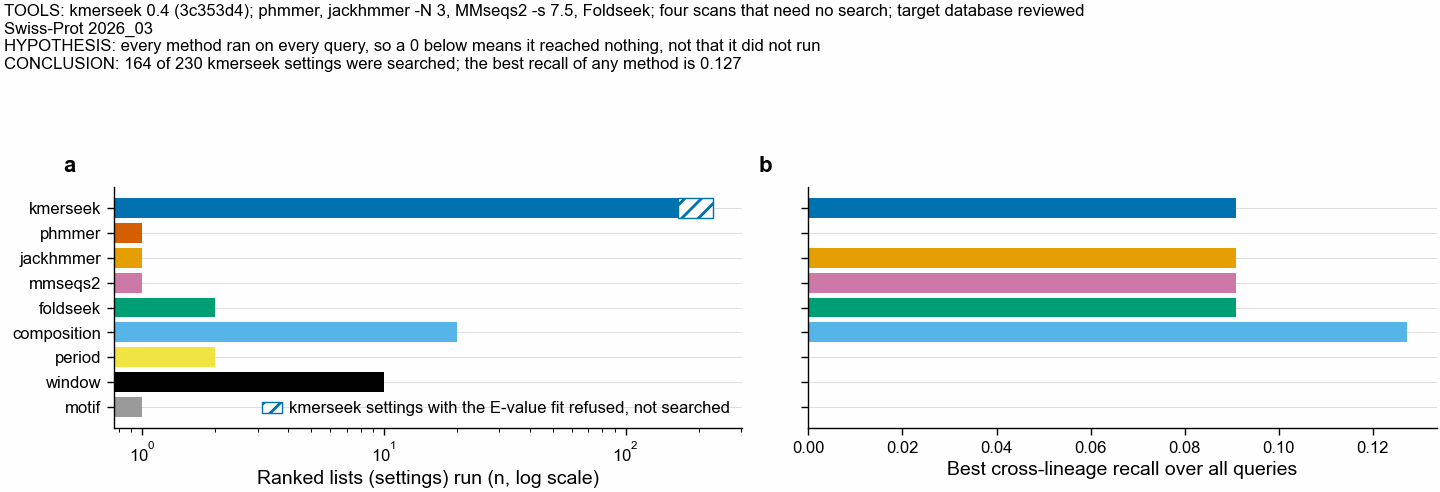

In [3]:
ran = (
    real.group_by("method")
    .agg(
        pl.col("setting_label").n_unique().alias("ranked_lists"),
        pl.col("query_id").n_unique().alias("queries_ranked"),
        pl.col("n_found").max().alias("most_cross_lineage_found"),
        pl.col("recall").max().alias("best_recall"),
    )
    .with_columns(pl.col("method").cast(pl.Enum(METHOD_ORDER)))
    .sort("method")
)
print(ran)
print()
print(
    "kmerseek settings with a usable E-value fit: "
    f"{real.filter(pl.col('method') == 'kmerseek')['setting_label'].n_unique()} of {n_settings_total}"
)

n_searched = real.filter(pl.col("method") == "kmerseek")["setting_label"].n_unique()
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=2, sharey=True)
y = np.arange(ran.height)
methods = [str(m) for m in ran["method"]]
axs[0].barh(y, ran["ranked_lists"], color=[METHOD_COLOUR[m] for m in methods])
k = methods.index("kmerseek")
axs[0].barh(
    k,
    n_settings_total - n_searched,
    left=n_searched,
    color="white",
    edgecolor=METHOD_COLOUR["kmerseek"],
    hatch="////",
    linewidth=0.5,
    label="kmerseek settings with the E-value fit refused, not searched",
)
axs[1].barh(y, ran["best_recall"], color=[METHOD_COLOUR[m] for m in methods])
axs[0].set_yticks(y)
axs[0].set_yticklabels(methods)
axs[0].invert_yaxis()
axs[0].set_xscale("log")
axs[0].set_xlabel("Ranked lists (settings) run (n, log scale)")
axs[1].set_xlabel("Best cross-lineage recall over all queries")
for ax in axs:
    ax.grid(axis="y", which="major")
    ax.set_axisbelow(True)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
legend_in_axes(axs[0], loc="lower right")
header(
    fig,
    "kmerseek 0.4 (3c353d4); phmmer, jackhmmer -N 3, MMseqs2 -s 7.5, Foldseek; four scans "
    "that need no search; target database reviewed Swiss-Prot 2026_03",
    "every method ran on every query, so a 0 below means it reached nothing, not that it "
    "did not run",
    f"{n_searched} of {n_settings_total} kmerseek settings were searched; the best recall of "
    f"any method is {float(ran['best_recall'].max()):.3f}",
)
pf.save(fig, FIGURES / "295_SF3_methods_run_swissprot_2026_03")

## 3. F1: the lineage grid. Only five squares off the diagonal are not zero

Rows are the query's lineage, columns the target's. A square holds how many ice-binding
proteins of that target lineage the query reached, taking the best of that method's
settings. The diagonal is grey because a hit on the query's own lineage is never counted:
only off-diagonal squares test reach across lineages.

Read it as a map of where any method gets out of its own lineage. Four methods reach the
same five fungal proteins from the bacterial query, and one scan reaches seven fish type I
proteins from the AFGP query. Every other square is zero.

shape: (5, 4)
┌─────────────┬───────────────┬────────────────────┬─────────┐
│ method      ┆ query_lineage ┆ target_lineage     ┆ n_found │
│ ---         ┆ ---           ┆ ---                ┆ ---     │
│ str         ┆ str           ┆ str                ┆ i64     │
╞═════════════╪═══════════════╪════════════════════╪═════════╡
│ composition ┆ 2 fish, AFGP  ┆ 1 fish, type I AFP ┆ 7       │
│ foldseek    ┆ 7 bacteria    ┆ 8 other            ┆ 5       │
│ jackhmmer   ┆ 7 bacteria    ┆ 8 other            ┆ 5       │
│ kmerseek    ┆ 7 bacteria    ┆ 8 other            ┆ 5       │
│ mmseqs2     ┆ 7 bacteria    ┆ 8 other            ┆ 5       │
└─────────────┴───────────────┴────────────────────┴─────────┘


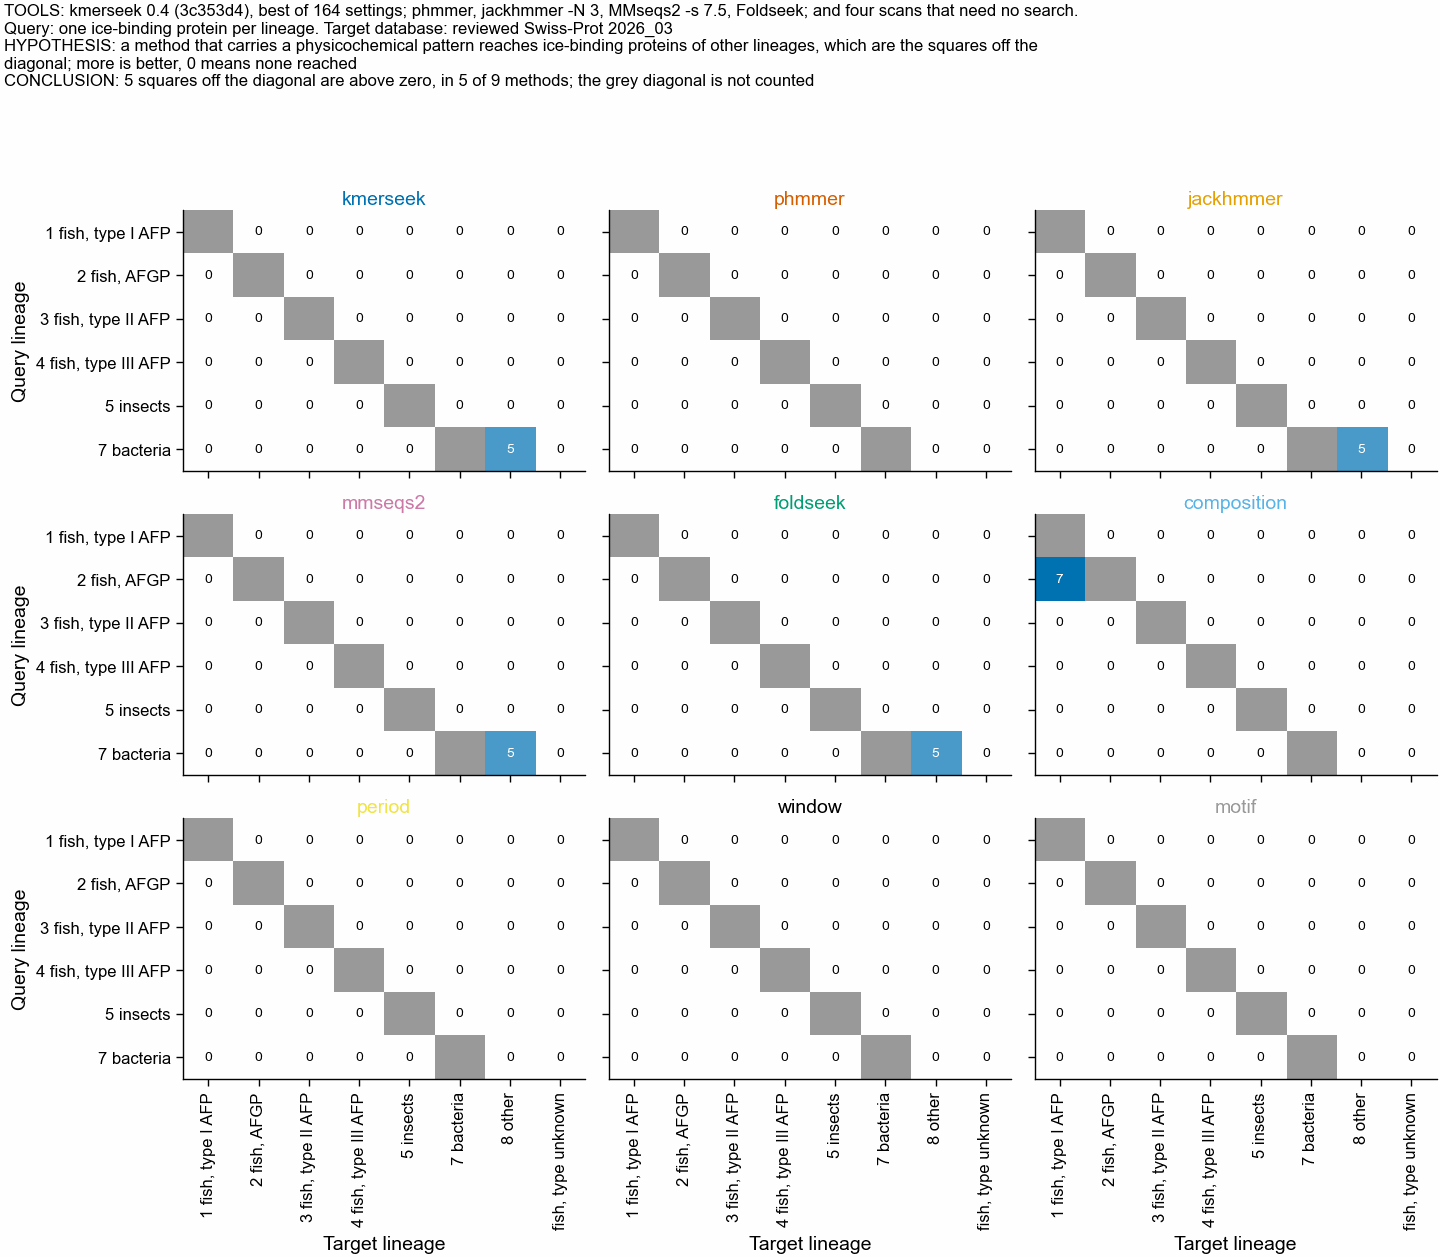

In [4]:
best_cell = grid.group_by("method", "query_lineage", "target_lineage").agg(
    pl.col("n_found").max().alias("n_found")
)
vmax = int(best_cell["n_found"].max())
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 150, ncols=3, nrows=3, sharex=True, sharey=True)
cmap = mpl.colors.LinearSegmentedColormap.from_list(
    "found", ["#ffffff", pf.OKABE_ITO["blue"]]
)
for ax, method in zip(axs.ravel(), METHOD_ORDER):
    m = np.zeros((len(QUERY_LINEAGES), len(TARGET_LINEAGES)))
    sub = best_cell.filter(pl.col("method") == method)
    for row in sub.iter_rows(named=True):
        if row["query_lineage"] in QUERY_LINEAGES:
            m[
                QUERY_LINEAGES.index(row["query_lineage"]),
                TARGET_LINEAGES.index(row["target_lineage"]),
            ] = row["n_found"]
    own = np.zeros_like(m, dtype=bool)
    for i, q in enumerate(QUERY_LINEAGES):
        if q in TARGET_LINEAGES:
            own[i, TARGET_LINEAGES.index(q)] = True
    ax.imshow(np.ma.masked_where(own, m), cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    ax.imshow(
        np.ma.masked_where(~own, np.ones_like(m)),
        cmap=mpl.colors.ListedColormap([pf.GREY]),
        vmin=0,
        vmax=1,
        aspect="auto",
    )
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            if own[i, j]:
                continue
            ax.text(
                j,
                i,
                int(m[i, j]),
                ha="center",
                va="center",
                color="white" if m[i, j] > vmax / 2 else "black",
                fontsize=5,
            )
    ax.set_title(method, color=METHOD_COLOUR[method], pad=2)
    ax.set_xticks(range(len(TARGET_LINEAGES)))
    ax.set_xticklabels(TARGET_LINEAGES, rotation=90)
    ax.set_yticks(range(len(QUERY_LINEAGES)))
    ax.set_yticklabels(QUERY_LINEAGES)
for ax in axs[-1]:
    ax.set_xlabel("Target lineage")
for ax in axs[:, 0]:
    ax.set_ylabel("Query lineage")
off = best_cell.filter(
    (pl.col("query_lineage") != pl.col("target_lineage")) & (pl.col("n_found") > 0)
)
print(off.sort("query_lineage", "method"))
header(
    fig,
    "kmerseek 0.4 (3c353d4), best of 164 settings; phmmer, jackhmmer -N 3, MMseqs2 -s 7.5, "
    "Foldseek; and four scans that need no search. Query: one ice-binding protein per lineage. "
    "Target database: reviewed Swiss-Prot 2026_03",
    "a method that carries a physicochemical pattern reaches ice-binding proteins of other "
    "lineages, which are the squares off the diagonal; more is better, 0 means none reached",
    f"{off.height} squares off the diagonal are above zero, in {off['method'].n_unique()} of "
    f"{len(METHOD_ORDER)} methods; the grey diagonal is not counted",
)
pf.save(fig, FIGURES / "295_F1_lineage_grid_swissprot_2026_03")

## 4. F2: cross-lineage recall, and what the controls reach

One bar per method per query, the best of that method's settings. The marks show what the
controls reach at the same score cutoff as the real query: a circle for null A, the
residues shuffled, and a square for null B, the repeat period kept and the word changed.
A control mark level with the bar would mean the method's hits do not depend on the
query's sequence at all.

Recall is out of every ice-binding protein outside the query's own lineage, which is 40
to 56 proteins depending on the query.

shape: (54, 6)
┌────────────────────┬─────────────┬────────────────────────────┬────────┬─────────┬───────────────┐
│ query_lineage      ┆ method      ┆ setting_label              ┆ recall ┆ n_found ┆ n_cross_truth │
│ ---                ┆ ---         ┆ ---                        ┆ ---    ┆ ---     ┆ ---           │
│ str                ┆ str         ┆ str                        ┆ f64    ┆ i64     ┆ i64           │
╞════════════════════╪═════════════╪════════════════════════════╪════════╪═════════╪═══════════════╡
│ 1 fish, type I AFP ┆ mmseqs2     ┆ default                    ┆ 0.0    ┆ 0       ┆ 47            │
│ 1 fish, type I AFP ┆ composition ┆ composition_aa20           ┆ 0.0    ┆ 0       ┆ 47            │
│ 1 fish, type I AFP ┆ kmerseek    ┆ dayhoff6.k11.s10.lcfalse.e ┆ 0.0    ┆ 0       ┆ 47            │
│                    ┆             ┆ xten…                      ┆        ┆         ┆               │
│ 1 fish, type I AFP ┆ period      ┆ period_hp_moment           ┆ 0.0    ┆ 0

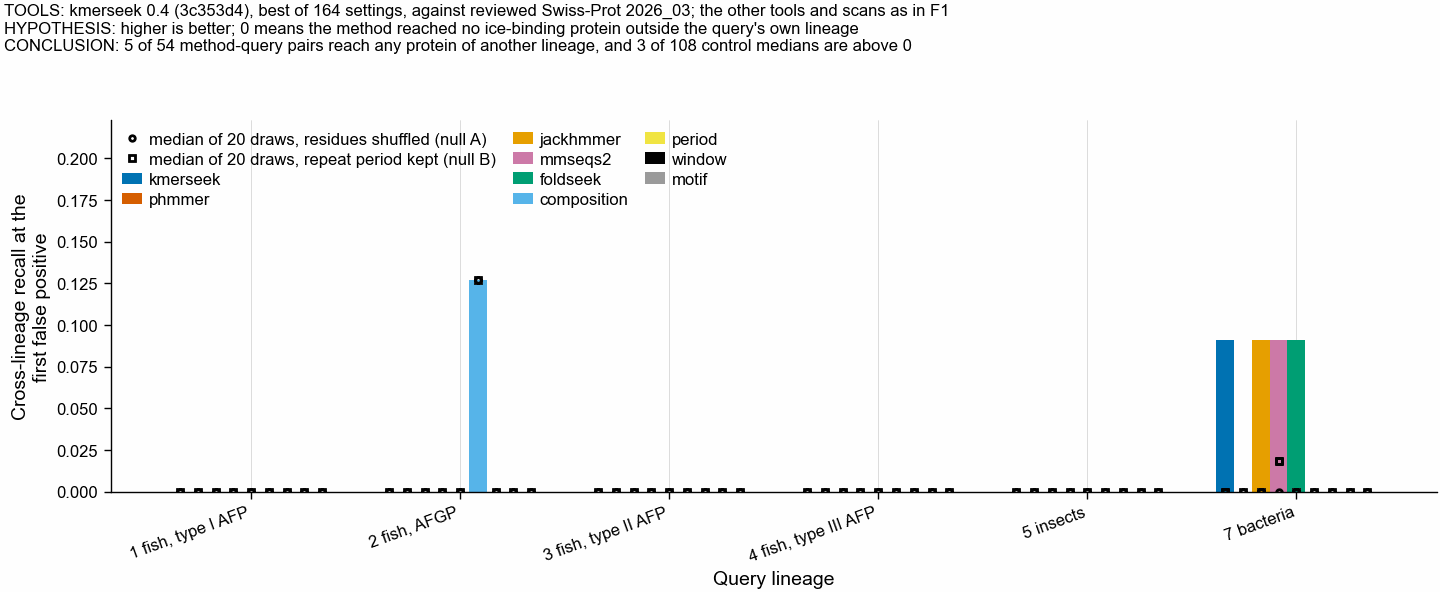

In [5]:
nulls = metrics.filter(pl.col("kind") != "real").with_columns(
    recall_at_real=pl.col("n_found_at_real_threshold") / pl.col("n_cross_truth")
)
best_per = (
    real.sort("recall", descending=True)
    .group_by("query_lineage", "method")
    .head(1)
    .select(
        "query_lineage", "method", "setting_label", "recall", "n_found", "n_cross_truth"
    )
)
null_med = (
    nulls.join(
        best_per.select("query_lineage", "method", "setting_label"),
        on=["query_lineage", "method", "setting_label"],
    )
    .group_by("query_lineage", "method", "kind")
    .agg(pl.col("recall_at_real").median().alias("median_recall"))
)
print(best_per.sort("query_lineage", "recall", descending=[False, True]))
print()
print(
    null_med.pivot(
        values="median_recall", index=["query_lineage", "method"], on="kind"
    ).sort("query_lineage")
)

fig, ax = pf.figure(pf.TWO_COLUMN_MM, 70)
width = 0.085
for k, method in enumerate(METHOD_ORDER):
    xs, ys = [], []
    for i, lineage in enumerate(QUERY_LINEAGES):
        row = best_per.filter(
            (pl.col("query_lineage") == lineage) & (pl.col("method") == method)
        )
        if not row.height:
            continue
        xs.append(i + (k - len(METHOD_ORDER) / 2) * width + width / 2)
        ys.append(row["recall"][0])
    ax.bar(xs, ys, width=width, color=METHOD_COLOUR[method], label=method)
    for kind, marker in [("nullA", "o"), ("nullB", "s")]:
        mx, my = [], []
        for x, lineage in zip(
            xs,
            [
                l
                for l in QUERY_LINEAGES
                if (
                    best_per.filter(
                        (pl.col("query_lineage") == l) & (pl.col("method") == method)
                    ).height
                )
            ],
        ):
            row = null_med.filter(
                (pl.col("query_lineage") == lineage)
                & (pl.col("method") == method)
                & (pl.col("kind") == kind)
            )
            if row.height:
                mx.append(x)
                my.append(row["median_recall"][0])
        ax.plot(
            mx,
            my,
            marker,
            color="black",
            markersize=2,
            markerfacecolor="none",
            linestyle="none",
            label=(
                {
                    "nullA": "median of 20 draws, residues shuffled (null A)",
                    "nullB": "median of 20 draws, repeat period kept (null B)",
                }[kind]
                if k == 0
                else None
            ),
        )
ax.set_ylim(0, max(0.02, float(best_per["recall"].max()) * 1.75))
ax.set_xticks(range(len(QUERY_LINEAGES)))
ax.set_xticklabels(QUERY_LINEAGES, rotation=20, ha="right")
ax.set_ylabel("Cross-lineage recall at the\nfirst false positive")
ax.set_xlabel("Query lineage")
ax.grid(axis="x", which="major")
ax.set_axisbelow(True)
legend_in_axes(ax, ncol=3, loc="upper left")
n_above = int((best_per["recall"] > 0).sum())
n_pairs = best_per.height
header(
    fig,
    "kmerseek 0.4 (3c353d4), best of 164 settings, against reviewed Swiss-Prot 2026_03; "
    "the other tools and scans as in F1",
    "higher is better; 0 means the method reached no ice-binding protein outside the "
    "query's own lineage",
    f"{n_above} of {n_pairs} method-query pairs reach any protein of another lineage, and "
    f"{int((null_med['median_recall'] > 0).sum())} of {null_med.height} control medians "
    "are above 0",
)
pf.save(fig, FIGURES / "295_F2_cross_lineage_recall_swissprot_2026_03")

## 5. F3: the residues of the only cross-lineage hits kmerseek makes

Every cross-lineage hit kmerseek makes above its threshold is the bacterial ice-binding
protein H7FWB6 against the Arctic yeast protein C7F6X3. Both carry UniProt's "Ice-binding
protein family" annotation, so this pair is related by ancestry, which is why jackhmmer,
MMseqs2 and Foldseek find it as well.

The block below is the aligned residues as kmerseek reports them: no gaps, coordinates
0-based and end-exclusive, with the hydrophobic-polar string of each sequence underneath
and a bar where the two agree.

53 residue blocks and 2 chained regions with no residue block
distinct pairs: ['H7FWB6__real vs B8XC03', 'H7FWB6__real vs B8XC03 (8 other)', 'H7FWB6__real vs B8XC04', 'H7FWB6__real vs B8XC04 (8 other)', 'H7FWB6__real vs C7F6X3 (8 other)', 'H7FWB6__real vs Q76CE6 (8 other)', 'H7FWB6__real vs Q76CE8 (8 other)']

shown: hsdm17.k6.s1.lcfalse.extend-c0.18
region_evalue 3.47, region_ka_bits 33.76, 30 of 49 identical, longest matching h/p run 10

query     131 LTTAVGDMQIAYDNAAGRLNPDFLNLGAGTIGGKTLTPGLYKWTSTLNI 180
              ||||| ||| |   | ||  ||| ||| |  ||  |||||||||     
target    144 LTTAVSDMQTAFNDATGRVTPDFTNLGGGELGGLVLTPGLYKWTGAVSV 193

query  h/p    hpphhpphphhhpphhpphphphhphphpphpppphphphhphppphph
              ||||||||| ||||| ||||||| ||| |||||  |||||||||| |||
target h/p    hpphhpphpphhpphppphphphpphpppphpphhhphphhphpphhph


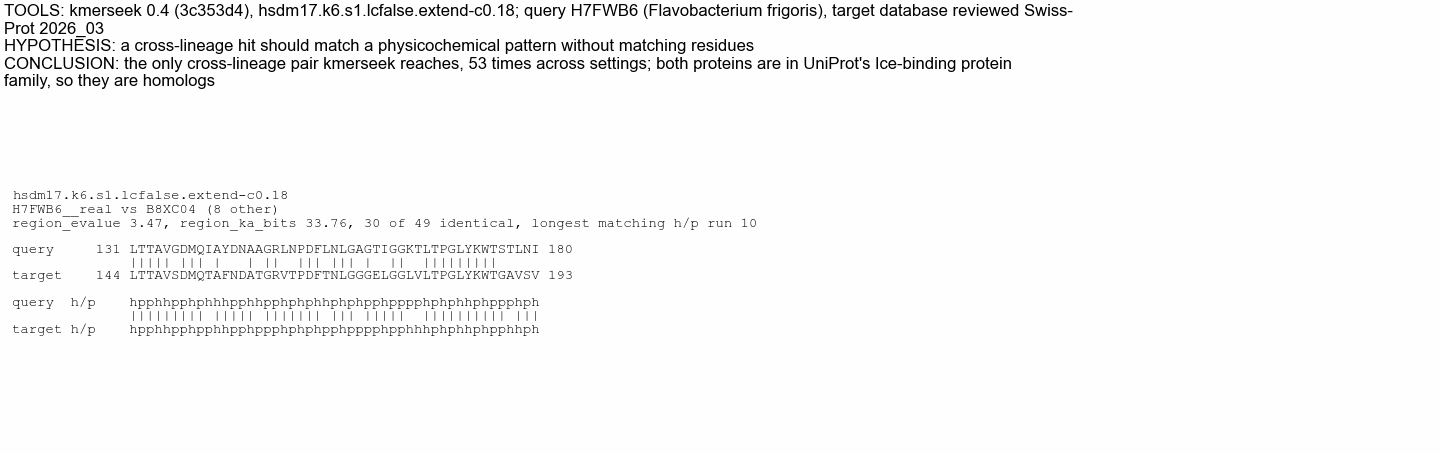

In [6]:
blocks, chained = [], []
for chunk in hits_md.split("\n## ")[1:]:
    head, _, body = chunk.partition("\n")
    setting, _, pair = head.partition(": ")
    stats = next((ln for ln in body.splitlines() if ln.strip()), "")
    m = re.search(r"```\n(.*?)```", body, re.S)
    if m:
        blocks.append(
            {
                "setting": setting,
                "pair": pair,
                "stats": stats,
                "text": m.group(1).rstrip("\n"),
            }
        )
    else:
        # A chained region: the query and target spans differ in length, so there are no
        # residues to line up. score.py writes the note instead of a block.
        chained.append({"setting": setting, "pair": pair, "stats": stats})
print(
    f"{len(blocks)} residue blocks and {len(chained)} chained regions with no residue block"
)
print(f"distinct pairs: {sorted({b['pair'] for b in blocks + chained})}")
chosen = next(
    (b for b in blocks if b["setting"] == verdict["chosen_setting"]), blocks[0]
)
print(f"\nshown: {chosen['setting']}\n{chosen['stats']}\n")
print(chosen["text"])

fig, ax = pf.figure(pf.TWO_COLUMN_MM, 48)
ax.axis("off")
ax.text(
    0.0,
    1.0,
    f"{chosen['setting']}\n{chosen['pair']}\n{chosen['stats']}\n\n{chosen['text']}",
    family="monospace",
    fontsize=5,
    va="top",
    ha="left",
    transform=ax.transAxes,
)
header(
    fig,
    f"kmerseek 0.4 (3c353d4), {chosen['setting']}; query H7FWB6 (Flavobacterium frigoris), "
    "target database reviewed Swiss-Prot 2026_03",
    "a cross-lineage hit should match a physicochemical pattern without matching residues",
    f"the only cross-lineage pair kmerseek reaches, {len(blocks)} times across settings; both "
    "proteins are in UniProt's Ice-binding protein family, so they are homologs",
)
pf.save(fig, FIGURES / "295_F3_kmerseek_cross_lineage_hit_residues_swissprot_2026_03")

## 6. SF2: what the controls reach, draw by draw

Each point is one of the 20 draws, counted at the real query's score cutoff, for the
kmerseek setting the rule chose. The real query's count is the cross. With 20 draws a
point cloud is the honest picture; a density curve over 20 values would invent a shape.

shape: (18, 5)
┌────────────────────┬───────┬────────┬─────┬─────────┐
│ query_lineage      ┆ kind  ┆ median ┆ max ┆ n_draws │
│ ---                ┆ ---   ┆ ---    ┆ --- ┆ ---     │
│ str                ┆ str   ┆ f64    ┆ i64 ┆ u32     │
╞════════════════════╪═══════╪════════╪═════╪═════════╡
│ 1 fish, type I AFP ┆ nullA ┆ 0.0    ┆ 0   ┆ 20      │
│ 1 fish, type I AFP ┆ nullB ┆ 0.0    ┆ 0   ┆ 20      │
│ 1 fish, type I AFP ┆ real  ┆ 0.0    ┆ 0   ┆ 1       │
│ 2 fish, AFGP       ┆ nullA ┆ 0.0    ┆ 0   ┆ 20      │
│ 2 fish, AFGP       ┆ nullB ┆ 0.0    ┆ 0   ┆ 20      │
│ …                  ┆ …     ┆ …      ┆ …   ┆ …       │
│ 5 insects          ┆ nullB ┆ 0.0    ┆ 0   ┆ 20      │
│ 5 insects          ┆ real  ┆ 0.0    ┆ 0   ┆ 1       │
│ 7 bacteria         ┆ nullA ┆ 0.0    ┆ 0   ┆ 20      │
│ 7 bacteria         ┆ nullB ┆ 0.0    ┆ 0   ┆ 20      │
│ 7 bacteria         ┆ real  ┆ 5.0    ┆ 5   ┆ 1       │
└────────────────────┴───────┴────────┴─────┴─────────┘


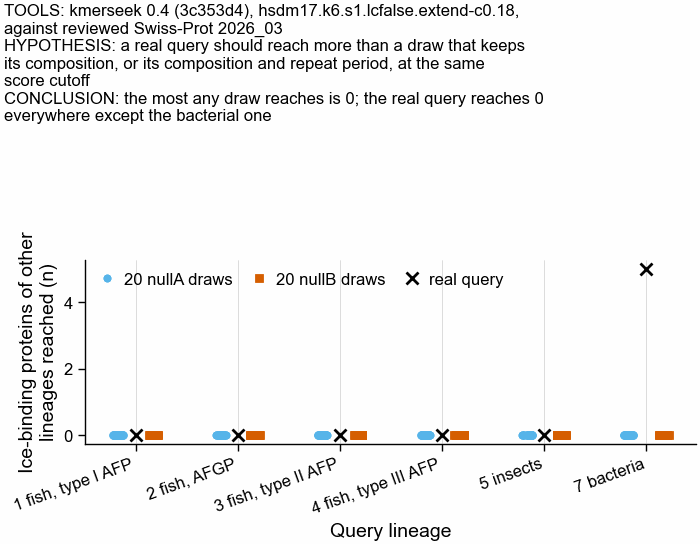

In [7]:
chosen_setting = verdict["chosen_setting"]
sub = metrics.filter(
    (pl.col("method") == "kmerseek") & (pl.col("setting_label") == chosen_setting)
)
print(
    sub.group_by("query_lineage", "kind")
    .agg(
        pl.col("n_found_at_real_threshold").median().alias("median"),
        pl.col("n_found_at_real_threshold").max().alias("max"),
        pl.len().alias("n_draws"),
    )
    .sort("query_lineage", "kind")
)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
rng = np.random.default_rng(0)
for kind, colour, marker in [
    ("nullA", pf.OKABE_ITO["sky_blue"], "o"),
    ("nullB", pf.OKABE_ITO["vermillion"], "s"),
]:
    for i, lineage in enumerate(QUERY_LINEAGES):
        v = sub.filter((pl.col("kind") == kind) & (pl.col("query_lineage") == lineage))[
            "n_found_at_real_threshold"
        ].to_numpy()
        if not len(v):
            continue
        dx = -0.17 if kind == "nullA" else 0.17
        ax.plot(
            i + dx + rng.uniform(-0.05, 0.05, len(v)),
            v,
            marker,
            color=colour,
            markersize=2,
            linestyle="none",
            label=f"20 {kind} draws" if i == 0 else None,
        )
for i, lineage in enumerate(QUERY_LINEAGES):
    v = sub.filter((pl.col("kind") == "real") & (pl.col("query_lineage") == lineage))[
        "n_found"
    ]
    if v.len():
        ax.plot(
            i,
            v[0],
            "x",
            color="black",
            markersize=4,
            label="real query" if i == 0 else None,
        )
ax.set_xticks(range(len(QUERY_LINEAGES)))
ax.set_xticklabels(QUERY_LINEAGES, rotation=20, ha="right")
ax.set_ylabel("Ice-binding proteins of other\nlineages reached (n)")
ax.set_xlabel("Query lineage")
ax.grid(axis="x", which="major")
ax.set_axisbelow(True)
legend_in_axes(ax, ncol=3, loc="upper left")
header(
    fig,
    f"kmerseek 0.4 (3c353d4), {chosen_setting}, against reviewed Swiss-Prot 2026_03",
    "a real query should reach more than a draw that keeps its composition, or its "
    "composition and repeat period, at the same score cutoff",
    f"the most any draw reaches is {int(sub.filter(pl.col('kind') != 'real')['n_found_at_real_threshold'].max())}; "
    "the real query reaches 0 everywhere except the bacterial one",
)
pf.save(fig, FIGURES / "295_SF2_null_draws_swissprot_2026_03")

## 7. The decision

The three numbers of the rule, for each held-out lineage, straight from
`verdict.json`.

shape: (2, 9)
┌────────────┬────────────┬────────────┬────────────┬───┬────────────┬───────────┬────────┬────────┐
│ held-out   ┆ kmerseek   ┆ best compo ┆ margin     ┆ … ┆ which      ┆ real      ┆ null B ┆ passes │
│ lineage    ┆ recall     ┆ sition or  ┆ (rule      ┆   ┆ ---        ┆ reached   ┆ median ┆ ---    │
│ ---        ┆ ---        ┆ period     ┆ needs >=   ┆   ┆ str        ┆ ---       ┆ ---    ┆ bool   │
│ str        ┆ f64        ┆ ---        ┆ 0.10)      ┆   ┆            ┆ f64       ┆ f64    ┆        │
│            ┆            ┆ f64        ┆ ---        ┆   ┆            ┆           ┆        ┆        │
│            ┆            ┆            ┆ f64        ┆   ┆            ┆           ┆        ┆        │
╞════════════╪════════════╪════════════╪════════════╪═══╪════════════╪═══════════╪════════╪════════╡
│ 2 fish,    ┆ 0.0        ┆ 0.127273   ┆ -0.127273  ┆ … ┆ compositio ┆ 0.0       ┆ 0.0    ┆ false  │
│ AFGP       ┆            ┆            ┆            ┆   ┆ n_wass14   ┆       

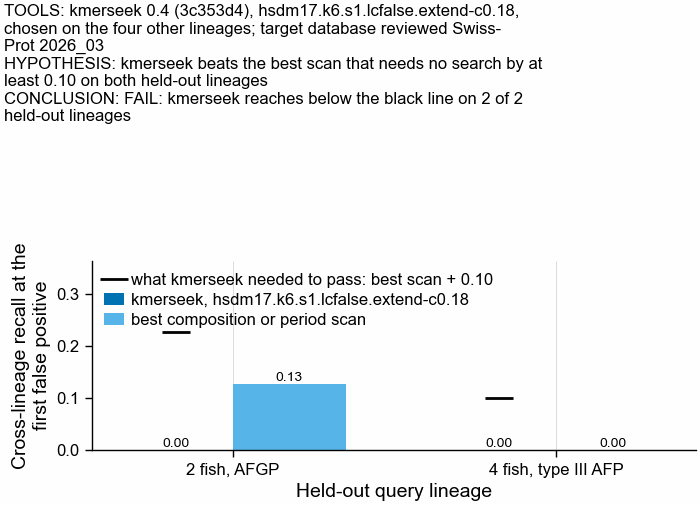

In [8]:
rows = []
for lineage, d in verdict["per_held_out_lineage"].items():
    rows.append(
        {
            "held-out lineage": lineage,
            "kmerseek recall": d["kmerseek_recall"],
            "best composition or period": d["best_composition_or_period_recall"],
            "margin (rule needs >= 0.10)": d["margin_over_composition_and_period"],
            "best of every no-search method": d["best_no_search_recall"],
            "which": d["best_no_search_list"],
            "real reached": d["real_n_found"],
            "null B median": d["null_b_median_n_found_at_real_threshold"],
            "passes": d["passes_margin_rule"] and d["passes_null_b_rule"],
        }
    )
decision = pl.DataFrame(rows)
print(decision)
print()
print(f"chosen setting:            {verdict['chosen_setting']}")
print(f"chosen on:                 {', '.join(verdict['chosen_on'])}")
print(f"its in-sample mean recall: {verdict['chosen_mean_recall_in_sample']:.4f}")
print(f"held-out lineages passing: {len(verdict['held_out_lineages_passing'])} of 2")
print()
print(f"VERDICT: {verdict['verdict']}")

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 50)
x = np.arange(decision.height)
w = 0.35
ax.bar(
    x - w / 2,
    decision["kmerseek recall"],
    width=w,
    color=METHOD_COLOUR["kmerseek"],
    label=f"kmerseek, {verdict['chosen_setting']}",
)
ax.bar(
    x + w / 2,
    decision["best composition or period"],
    width=w,
    color=METHOD_COLOUR["composition"],
    label="best composition or period scan",
)
ax.plot(
    x - w / 2,
    decision["best composition or period"] + 0.10,
    "_",
    color="black",
    markersize=10,
    markeredgewidth=1,
    linestyle="none",
    label="what kmerseek needed to pass: best scan + 0.10",
)
for xi, (k_val, s_val) in enumerate(
    zip(decision["kmerseek recall"], decision["best composition or period"])
):
    for dx, v in [(-w / 2, k_val), (w / 2, s_val)]:
        ax.text(xi + dx, v, f"{v:.2f}", ha="center", va="bottom", fontsize=5)
ax.set_xticks(x)
ax.set_xticklabels(decision["held-out lineage"])
ax.set_ylim(0, float((decision["best composition or period"] + 0.10).max()) * 1.6)
ax.set_ylabel("Cross-lineage recall at the\nfirst false positive")
ax.set_xlabel("Held-out query lineage")
ax.grid(axis="x", which="major")
ax.set_axisbelow(True)
legend_in_axes(ax, loc="upper left")
header(
    fig,
    f"kmerseek 0.4 (3c353d4), {verdict['chosen_setting']}, chosen on the four other lineages; "
    "target database reviewed Swiss-Prot 2026_03",
    "kmerseek beats the best scan that needs no search by at least 0.10 on both held-out lineages",
    f"{verdict['verdict']}: kmerseek reaches below the black line on "
    f"{decision.height - len(verdict['held_out_lineages_passing'])} of {decision.height} held-out lineages",
)
pf.save(fig, FIGURES / "295_SF4_decision_swissprot_2026_03")

## 8. Three more patterns that evolved more than once: truth sets only, no search yet

The same test can be asked of any protein pattern that arose separately in unrelated
lineages. Three more were built with `scripts/convergence_classes_truth.py`, from the
UniProt REST API, release 2026_03:

* **Adhesive (B).** Underwater glue rich in tyrosine and lysine, where the tyrosine
  becomes DOPA after translation. Mussels and sandcastle worms arrived at it separately.
  Barnacle cement does the same job with a different chemistry and is the control.
* **Shell matrix (C).** Aspartate- and glutamate-rich, low-complexity proteins in
  mollusc shells, coral skeletons, sea-urchin tests and vertebrate bone.
* **Silk (D).** Long repeats of short glycine- and alanine-rich units. Spiders and the
  moths-plus-caddisflies clade are two separate origins. Bee, ant and hornet silks are
  coiled coils, a different pattern, and are the control.

An entry counts as a cross-lineage target only if it is reviewed (Swiss-Prot), sits in a
lineage that carries the pattern, and, for shell and silk, carries the pattern itself by
its composition or repeats. A class is a benchmark only if it has at least 20 such entries
in at least 2 lineages; otherwise it can only be a case study. The searches have not been
run for any of the three.

shape: (3, 5)
┌──────────┬─────────┬─────────────────┬───────────────────────────┬────────────┐
│ class    ┆ entries ┆ counted targets ┆ pattern lineages with one ┆ result     │
│ ---      ┆ ---     ┆ ---             ┆ ---                       ┆ ---        │
│ str      ┆ i64     ┆ i64             ┆ i64                       ┆ str        │
╞══════════╪═════════╪═════════════════╪═══════════════════════════╪════════════╡
│ adhesive ┆ 10      ┆ 6               ┆ 1                         ┆ case study │
│ shell    ┆ 626     ┆ 75              ┆ 4                         ┆ benchmark  │
│ silk     ┆ 65      ┆ 3               ┆ 2                         ┆ case study │
└──────────┴─────────┴─────────────────┴───────────────────────────┴────────────┘

shape: (12, 4)
┌─────────────────────────────────┬─────────┬─────────────┬──────────┐
│ lineage                         ┆ counted ┆ not_counted ┆ class    │
│ ---                             ┆ ---     ┆ ---         ┆ ---      │
│ str              

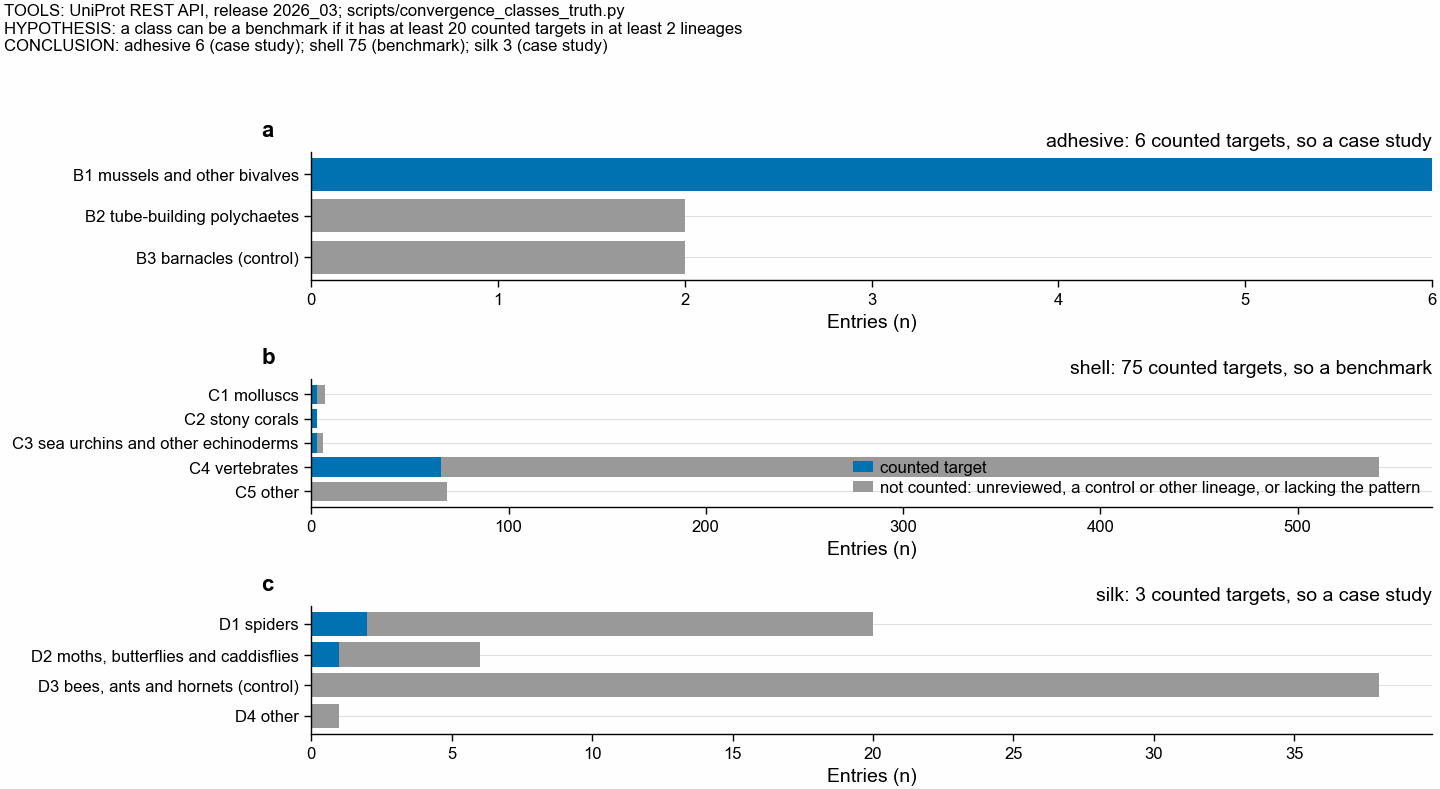

In [9]:
CLASS_PATTERN_LINEAGES = {
    "adhesive": ["B1 mussels and other bivalves", "B2 tube-building polychaetes"],
    "shell": [
        "C1 molluscs",
        "C2 stony corals",
        "C3 sea urchins and other echinoderms",
        "C4 vertebrates",
    ],
    "silk": ["D1 spiders", "D2 moths, butterflies and caddisflies"],
}
MIN_CROSS_TARGETS, MIN_QUERY_LINEAGES = 20, 2

gate_rows, lineage_rows = [], []
for cls, pattern in CLASS_PATTERN_LINEAGES.items():
    t = pl.read_csv(
        f"../data/convergence_{cls}/truth_set.tsv",
        separator="\t",
        infer_schema_length=0,
    )
    counted = (pl.col("tier") == "Swiss-Prot") & pl.col("lineage").is_in(pattern)
    if cls == "shell":
        counted = counted & (pl.col("kind") == "acidic or low complexity")
    if cls == "silk":
        counted = counted & (pl.col("kind") != "neither")
    t = t.with_columns(counted=counted)
    usable = t.filter("counted")
    n_lineages = usable["lineage"].n_unique()
    gate_rows.append(
        {
            "class": cls,
            "entries": t.height,
            "counted targets": usable.height,
            "pattern lineages with one": n_lineages,
            "result": (
                "benchmark"
                if usable.height >= MIN_CROSS_TARGETS
                and n_lineages >= MIN_QUERY_LINEAGES
                else "case study"
            ),
        }
    )
    lineage_rows.append(
        t.group_by("lineage")
        .agg(
            pl.col("counted").sum().alias("counted"),
            (~pl.col("counted")).sum().alias("not_counted"),
        )
        .with_columns(pl.lit(cls).alias("class"))
    )
gate = pl.DataFrame(gate_rows)
per_class_lineage = pl.concat(lineage_rows).sort("class", "lineage")
print(gate)
print()
print(per_class_lineage)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, nrows=3)
for ax, cls in zip(axs, CLASS_PATTERN_LINEAGES):
    sub = per_class_lineage.filter(pl.col("class") == cls)
    y = np.arange(sub.height)
    ax.barh(y, sub["counted"], color=pf.OKABE_ITO["blue"], label="counted target")
    ax.barh(
        y,
        sub["not_counted"],
        left=sub["counted"],
        color=pf.GREY,
        label="not counted: unreviewed, a control or other lineage, or lacking the pattern",
    )
    ax.set_yticks(y)
    ax.set_yticklabels(sub["lineage"])
    ax.invert_yaxis()
    ax.set_xlabel("Entries (n)")
    g = gate.filter(pl.col("class") == cls).row(0, named=True)
    ax.set_title(
        f"{cls}: {g['counted targets']} counted targets, so a {g['result']}",
        loc="right",
        pad=2,
    )
    ax.grid(axis="y", which="major")
    ax.set_axisbelow(True)
for ax, letter in zip(axs, "abc"):
    pf.panel_label(ax, letter)
legend_in_axes(axs[1], loc="lower right")
header(
    fig,
    "UniProt REST API, release 2026_03; scripts/convergence_classes_truth.py",
    f"a class can be a benchmark if it has at least {MIN_CROSS_TARGETS} counted targets in "
    f"at least {MIN_QUERY_LINEAGES} lineages",
    "; ".join(
        f"{r['class']} {r['counted targets']} ({r['result']})" for r in gate_rows
    ),
)
pf.save(fig, FIGURES / "295_SF5_other_classes_truth_sets_uniprot_2026_03")

## Summary and conclusions

**Verdict: FAIL.** No kmerseek setting reaches ice-binding proteins of another lineage
better than a scan that needs no search. Neither held-out lineage passes, and the rule
needs both.

The three numbers of the rule, for the chosen setting hsdm17 k=6 scaled=1 with mismatch
penalty 0.18, picked on the four in-sample lineages where its mean cross-lineage recall
was 0.0227:

| Held-out lineage | kmerseek recall | best scan with no search | margin (needs >= 0.10) |
|---|---|---|---|
| 2 fish, AFGP | 0.000 | 0.127 (composition in the wass14 alphabet) | -0.127 |
| 4 fish, type III | 0.000 | 0.000 | 0.000 |

**Claim sentences.**

1. Over 164 searchable settings and six queries, kmerseek reached an ice-binding protein
   of another lineage from one query only, the bacterial one, finding 5 of 55 (recall
   0.091); jackhmmer, MMseqs2 and Foldseek each found the same 5, so kmerseek added
   nothing there.
2. Those 5 proteins and the query all carry UniProt's "Ice-binding protein family"
   annotation, so the one place any method crossed a lineage boundary is a family related
   by ancestry, not a pattern shared without it.
3. From the five fish and insect queries, no kmerseek setting reached any ice-binding
   protein of another lineage: 0 of 164 settings for each query. From the bacterial
   query, 24 of the 164 settings reached at least one.
4. The only cross-lineage reach that ordinary sequence search misses came from a method
   with no search: the composition scan in the wass14 alphabet reached 7 of 55 fish type I
   proteins from the AFGP query, where every kmerseek setting reached 0. All 40 control
   draws of that query reached the same 7, as they must: a shuffle keeps the composition,
   so this reach comes from the AFGP query's alanine- and threonine-rich composition, not
   from the order of its residues.
5. The Kyte-Doolittle hydropathy window reached nothing from any real query, in any of its
   10 lists.
6. For the kmerseek setting the rule chose, every control draw reached 0 ice-binding
   proteins at the real query's score cutoff. The null rule is satisfied only because the
   real counts are 0 too, so it says nothing here.

**What this decides.** The paper cannot claim from this test that kmerseek finds proteins
sharing a physicochemical pattern without shared ancestry. The one cross-lineage pair it
reaches is a homolog pair that three other tools also find.

**What this test cannot say.** Four limits, each visible in the data above:

* Plants have no reviewed ice-binding protein, so the held-out half is two lineages, both
  fish, and the rule needed both.
* 44 of the 59 truth entries are fish, so most of the possible cross-lineage reach is
  between fish types, which arose from different genes but in one lineage.
* 66 of the 230 settings could not be searched at all, their Karlin-Altschul fit refused,
  so the sweep is 164 settings wide, not 230.
* A single query per lineage was chosen by its count of experimental evidence lines. A
  different query from the same lineage could behave differently, and nothing here tests
  that.

**Next.** The ice-binding test is the only class with a search run. Section 8 shows the
truth sets for the other three classes: only the shell-matrix class has enough reviewed
entries to be scored as a benchmark; adhesive and silk proteins can only be case studies.